#Step 1: Create the dataset in your notebook

In [93]:
import pandas as pd
import numpy as np

In [94]:
data = {
    'area_sqm': [85, 100, 120, 95, 140, 110, 75, 130, 105, 90, 150, 115, 80, 125, 135],
    'rooms': [2, 3, 3, 2, 4, 3, 2, 4, 3, 2, 4, 3, 2, 3, 4],
    'age_years': [10, 8, 5, 12, 3, 7, 15, 4, np.nan, 11, 2, 6, 14, 4, 3],
    'distance_center_km': [9.0, 7.5, 6.0, 8.0, 4.5, 6.8, 11.0, 5.0, 7.0, 9.5, 3.5, 6.2, 10.5, 5.5, np.nan],
    'price_k_sar': [430, 520, 650, 470, 820, 590, 380, 760, 560, 450, 900, 630, 400, 710, 790]
}

In [95]:
df = pd.DataFrame(data)

In [96]:
df.head()

,area_sqm,rooms,age_years,distance_center_km,price_k_sar
0,85,2,10.0,9.0,430
1,100,3,8.0,7.5,520
2,120,3,5.0,6.0,650
3,95,2,12.0,8.0,470
4,140,4,3.0,4.5,820


In [97]:
display(df)

,area_sqm,rooms,age_years,distance_center_km,price_k_sar
0,85,2,10.0,9.0,430
1,100,3,8.0,7.5,520
2,120,3,5.0,6.0,650
3,95,2,12.0,8.0,470
4,140,4,3.0,4.5,820
5,110,3,7.0,6.8,590
6,75,2,15.0,11.0,380
7,130,4,4.0,5.0,760
8,105,3,NaN,7.0,560
9,90,2,11.0,9.5,450


# Step 2: Look at the data

In [98]:
print('First 5 rows:')
display(df.head())

print('Shape:', df.shape)

print('Columns:')
print(df.columns.tolist())

First 5 rows:


,area_sqm,rooms,age_years,distance_center_km,price_k_sar
0,85,2,10.0,9.0,430
1,100,3,8.0,7.5,520
2,120,3,5.0,6.0,650
3,95,2,12.0,8.0,470
4,140,4,3.0,4.5,820


Shape: (15, 5)
Columns:
['area_sqm', 'rooms', 'age_years', 'distance_center_km', 'price_k_sar']


#check for missig values

In [99]:
print('Missing values in each column:')
print(df.isnull().sum())

Missing values in each column:
area_sqm              0
rooms                 0
age_years             1
distance_center_km    1
price_k_sar           0
dtype: int64


#Step 4: Preprocess the data

In [100]:
df['age_years'] = df['age_years'].fillna(df['age_years'].median())

df['distance_center_km'] = df['distance_center_km'].fillna(
    df['distance_center_km'].median()
)

print('Missing values after preprocessing:')
print(df.isnull().sum())

Missing values after preprocessing:
area_sqm              0
rooms                 0
age_years             0
distance_center_km    0
price_k_sar           0
dtype: int64


#Step 5: Create the features X and the target y

In [101]:
X = df[["area_sqm" , "rooms" , "age_years" , "distance_center_km"]]
y = df["price_k_sar"]

print('Features X:')
display(X.head())

print('Target y:')
display(y.head())

Features X:


,area_sqm,rooms,age_years,distance_center_km
0,85,2,10.0,9.0
1,100,3,8.0,7.5
2,120,3,5.0,6.0
3,95,2,12.0,8.0
4,140,4,3.0,4.5


Target y:


,price_k_sar
0,430
1,520
2,650
3,470
4,820


#Step 6: Split the data into training and testing

In [102]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Training set size:', X_train.shape[0])
print('Testing set size:', X_test.shape[0])

Training set size: 12
Testing set size: 3


#Step 7: Train a Linear Regression model


In [103]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print('Model trained successfully.')

Model trained successfully.


#Step 8: Make predictions on the test data


In [104]:
y_pred = model.predict(X_test)

print('Predictions on test data:')
print(y_pred)

results = pd.DataFrame({
    'Actual_Price_k_SAR': y_test.reset_index(drop=True),
    'Predicted_Price_k_SAR': y_pred.round(1)
})

display(results)

Predictions on test data:
[451.83623761 627.19756641 403.41111014]


,Actual_Price_k_SAR,Predicted_Price_k_SAR
0,450,451.8
1,630,627.2
2,430,403.4


#Step 9: Evaluate the model using MAE

In [105]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test, y_pred)

print(f'MAE: {mae:.2f} thousand SAR')

MAE: 10.41 thousand SAR


#Step 10: Use the model for one new apartment

In [106]:
new_apartment = pd.DataFrame([{
    'area_sqm': 1000000000000000000000,
    'rooms': 3,
    'age_years': 4,
    'distance_center_km': 5.0
}])

predicted_price = model.predict(new_apartment)[0]
print(f'Predicted price: {predicted_price:.1f} thousand SAR')
print(f'Predicted price: {predicted_price * 1000:,.0f} SAR')

Predicted price: 7909796742840206753792.0 thousand SAR
Predicted price: 7,909,796,742,840,206,342,750,208 SAR


# Plot 1: Histogram — Look at apartment prices
What this plot shows: A histogram shows how the apartment prices are distributed. It helps us see which price
ranges appear most often.

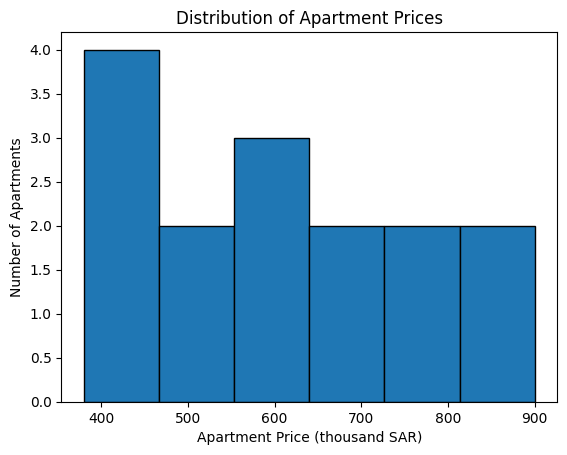

In [107]:
import matplotlib.pyplot as plt

plt.hist(df['price_k_sar'], bins=6, edgecolor='black')
plt.xlabel('Apartment Price (thousand SAR)')
plt.ylabel('Number of Apartments')
plt.title('Distribution of Apartment Prices')
plt.show()

# Plot 2: Scatter Plot — Area vs. Price
What this plot shows: A scatter plot helps us see the relationship between two numeric variables. Here, each dot
represents one apartment.

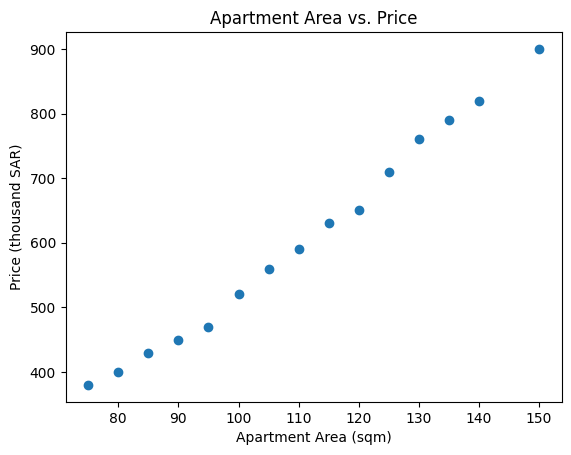

In [108]:
plt.scatter(df['area_sqm'], df['price_k_sar'])

plt.xlabel('Apartment Area (sqm)')
plt.ylabel('Price (thousand SAR)')
plt.title('Apartment Area vs. Price')

plt.show()

Note: scatter plot is for comparing two features while the histogram to show the distribution of 1 feature